In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import zipfile

# Load the Kaggle CSV; upload it in Colab if it is not in the current folder.
file_path = Path("AB_NYC_2019.csv")
if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_file = Path(next(iter(uploaded)))
        # If a zip archive was uploaded, extract it to find the CSV
        if uploaded_file.suffix == ".zip":
            with zipfile.ZipFile(uploaded_file, 'r') as zip_ref:
                zip_ref.extractall(".")
    except ImportError:
        raise FileNotFoundError("Place AB_NYC_2019.csv beside this notebook and run again.")

if not file_path.exists():
    raise FileNotFoundError("Could not locate AB_NYC_2019.csv. Please upload the correct dataset.")

df = pd.read_csv(file_path)
print("Dataset shape:", df.shape)
display(df.head())
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))

Saving archive.zip to archive (1).zip
Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


,column,dtype
0,id,int64
1,name,object
2,host_id,int64
3,host_name,object
4,neighbourhood_group,object
5,neighbourhood,object
6,latitude,float64
7,longitude,float64
8,room_type,object
9,price,int64


In [3]:
# Classify columns by measurement type.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical columns:", numeric_cols)
print("Categorical/text columns:", categorical_cols)

# Missing-value counts and percentages for every column.
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)


Numerical columns: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical/text columns: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


,missing_count,missing_percent
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03
neighbourhood_group,0,0.00
neighbourhood,0,0.00
id,0,0.00
host_id,0,0.00
longitude,0,0.00
latitude,0,0.00


In [4]:
# Check whether missing reviews_per_month correspond to zero reviews.
if {"reviews_per_month", "number_of_reviews"}.issubset(df.columns):
    print(df.loc[df["reviews_per_month"].isna(), "number_of_reviews"].value_counts(dropna=False).head())

# A missing review date/month usually means no reviews were recorded.
# Fill reviews_per_month with 0 only for listings with zero reviews; use median otherwise.
if "reviews_per_month" in df.columns:
    zero_review = df.get("number_of_reviews", pd.Series(index=df.index, dtype=float)).fillna(0).eq(0)
    df.loc[df["reviews_per_month"].isna() & zero_review, "reviews_per_month"] = 0
    df["reviews_per_month"] = df["reviews_per_month"].fillna(df["reviews_per_month"].median())

# Drop the high-missing date column and identifiers/text fields that are not useful predictors.
drop_cols = [c for c in ["last_review", "id", "name", "host_id", "host_name", "neighbourhood", "host_name", "last_review"] if c in df.columns]
df = df.drop(columns=list(dict.fromkeys(drop_cols)))
print("Dropped columns:", list(dict.fromkeys(drop_cols)))
print("Shape after cleaning:", df.shape)


number_of_reviews
0    10052
Name: count, dtype: int64
Dropped columns: ['last_review', 'id', 'name', 'host_id', 'host_name', 'neighbourhood']
Shape after cleaning: (48895, 10)


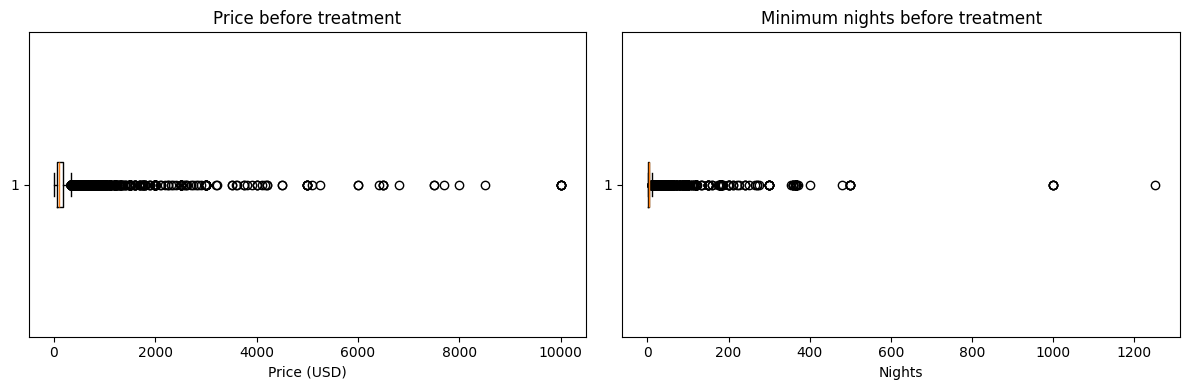

Rows retained: 45,748 of 48,895
95th-percentile price cap: $355.00; minimum_nights cap: 30


In [5]:
# Visualise price and minimum_nights before treatment.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(df["price"].dropna(), vert=False)
axes[0].set_title("Price before treatment")
axes[0].set_xlabel("Price (USD)")
axes[1].boxplot(df["minimum_nights"].dropna(), vert=False)
axes[1].set_title("Minimum nights before treatment")
axes[1].set_xlabel("Nights")
plt.tight_layout()
plt.show()

# Keep the typical consumer market using the assignment's 95th-percentile rule.
price_cap = df["price"].quantile(0.95)
nights_cap = df["minimum_nights"].quantile(0.95)
before = len(df)
df = df[(df["price"] > 0) & (df["price"] <= price_cap) & (df["minimum_nights"] <= nights_cap)]
print(f"Rows retained: {len(df):,} of {before:,}")
print(f"95th-percentile price cap: ${price_cap:.2f}; minimum_nights cap: {nights_cap:.0f}")


In [6]:
# Remove columns that directly identify a listing or are unsuitable for this baseline.
# neighbourhood is omitted because its 200+ categories create unnecessary dimensionality.
model_df = df.copy()
unused = [c for c in ["neighbourhood", "id", "name", "host_id", "host_name", "last_review"] if c in model_df.columns]
model_df = model_df.drop(columns=unused)

# Use selected numeric features plus the two categorical fields requested in the brief.
categorical = [c for c in ["neighbourhood_group", "room_type"] if c in model_df.columns]
numeric_candidates = ["minimum_nights", "number_of_reviews", "reviews_per_month",
                      "calculated_host_listings_count", "availability_365", "latitude", "longitude"]
numeric_features = [c for c in numeric_candidates if c in model_df.columns]
feature_cols = numeric_features + categorical
model_df = model_df[feature_cols + ["price"]].copy()

# Fill remaining numeric gaps with medians and categorical gaps with the most frequent value.
for c in numeric_features:
    model_df[c] = model_df[c].fillna(model_df[c].median())
for c in categorical:
    model_df[c] = model_df[c].fillna(model_df[c].mode().iloc[0] if not model_df[c].mode().empty else "Unknown")

X = pd.get_dummies(model_df[feature_cols], columns=categorical, drop_first=True, dtype=int)
y = model_df["price"]
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())


Feature matrix shape: (45748, 13)
Target shape: (45748,)


,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,1,9,0.21,6,365,40.64749,-73.97237,1,0,0,0,1,0
1,1,45,0.38,2,355,40.75362,-73.98377,0,1,0,0,0,0
2,3,0,0.00,1,365,40.80902,-73.94190,0,1,0,0,1,0
3,1,270,4.64,1,194,40.68514,-73.95976,1,0,0,0,0,0
4,10,9,0.10,1,0,40.79851,-73.94399,0,1,0,0,0,0


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))


Training rows: 36598 | Testing rows: 9150


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")


R-squared (R²): 0.4868
Mean Absolute Error (MAE): $38.32
Mean Squared Error (MSE): 2,760.62
Root Mean Squared Error (RMSE): $52.54


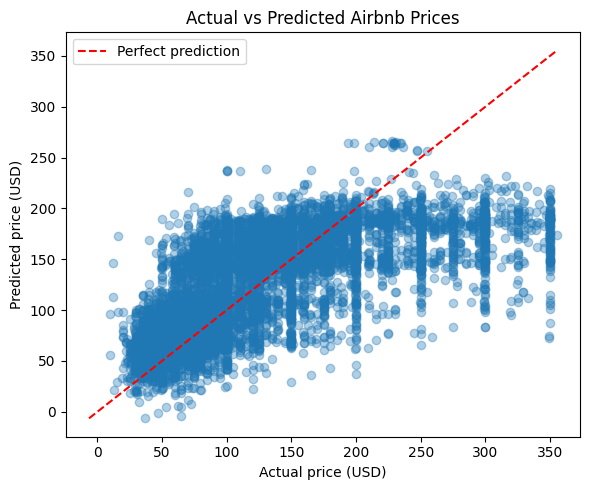

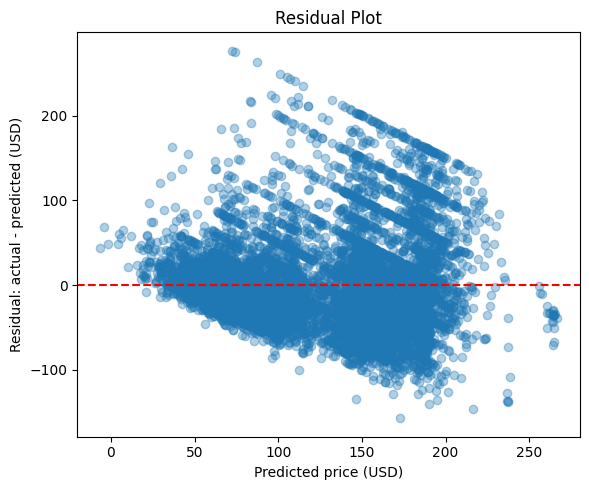

Test-set median price: $100.00
MAE for cheaper half: $29.01
MAE for more expensive half: $48.18
Interpretation: The model has a smaller average dollar error on cheaper listings.
Why: Linear Regression fits one linear relationship; unusual high-price listings and unobserved factors can make expensive listings harder to predict.


In [9]:
# Actual versus predicted prices, with the perfect-prediction diagonal.
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.35)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual price (USD)")
plt.ylabel("Predicted price (USD)")
plt.title("Actual vs Predicted Airbnb Prices")
plt.legend()
plt.tight_layout()
plt.show()

# Residuals should be centred near zero without a clear pattern.
residuals = y_test - y_pred
plt.figure(figsize=(6, 5))
plt.scatter(y_pred, residuals, alpha=0.35)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price (USD)")
plt.ylabel("Residual: actual - predicted (USD)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

# Compare errors for cheaper and more expensive listings using the test-set median.
results = pd.DataFrame({"actual": y_test, "predicted": y_pred})
results["absolute_error"] = (results["actual"] - results["predicted"]).abs()
median_price = results["actual"].median()
cheap_mae = results.loc[results["actual"] <= median_price, "absolute_error"].mean()
expensive_mae = results.loc[results["actual"] > median_price, "absolute_error"].mean()
print(f"Test-set median price: ${median_price:.2f}")
print(f"MAE for cheaper half: ${cheap_mae:.2f}")
print(f"MAE for more expensive half: ${expensive_mae:.2f}")
if cheap_mae < expensive_mae:
    print("Interpretation: The model has a smaller average dollar error on cheaper listings.")
elif expensive_mae < cheap_mae:
    print("Interpretation: The model has a smaller average dollar error on more expensive listings.")
else:
    print("Interpretation: Average dollar errors are approximately equal for both groups.")
print("Why: Linear Regression fits one linear relationship; unusual high-price listings and unobserved factors can make expensive listings harder to predict.")
